# Stock Price Analysis — Comparative Time-Series Analytics

## Section 1 — Project introduction

This notebook orchestrates a reusable Python package to examine historical prices, trading volume, returns, volatility, drawdowns, and common-date relationships for configurable securities. It demonstrates retrieval, provenance, validation, chronological indexing, Pandas resampling, rolling calculations, visual evidence, automated interpretation, and reproducible exports.

**Configured study:** Apple (`AAPL`) and Microsoft (`MSFT`), with enough observations for a 200-session moving average.

**Questions**

1. How did closing prices and price-only performance change over the selected period?
2. What changes when daily observations are resampled to Friday-ending weeks and calendar months?
3. How do trailing 20-session and 200-session averages describe historical trends?
4. How do absolute and relative share volumes compare?
5. What do daily returns, historical volatility, drawdown, and return correlation show?

> **Educational historical analysis only—not financial advice.** Past performance, historical volatility, moving averages, drawdowns, and correlations do not predict future results.

## Section 2 — Dependencies and central configuration

- **Pandas / NumPy** provide indexed, vectorized time-series operations.
- **yfinance** is the configured live data client.
- **Matplotlib** produces reproducible static charts.
- **`stock_analysis` modules** keep retrieval, validation, calculations, charts, and reporting testable outside this notebook.

Change `tickers`, `start_date`, `end_date`, `auto_adjust`, or `price_field` below to repeat the live workflow. `end_date` is exclusive for `yfinance`. For short display windows, download earlier warm-up history and use `display_start` so a 200-session average remains available.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import yfinance as yf
from IPython.display import Markdown, display

# Find the project when Jupyter starts in either the project root or notebooks/.
root_candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (path for path in root_candidates if (path / "src" / "stock_analysis").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from stock-price-time-series-analysis or notebooks/.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from stock_analysis.config import AnalysisConfig
from stock_analysis.data_loader import download_stock_data, load_local_stock_data
from stock_analysis.data_validation import validate_stock_data
from stock_analysis.metrics import (
    calculate_cumulative_performance,
    calculate_drawdown,
    calculate_return_correlation,
    create_summary_table,
)
from stock_analysis.preprocessing import align_common_dates, select_date_range
from stock_analysis.reporting import (
    DISCLAIMER,
    export_analysis_tables,
    generate_findings,
    write_markdown_report,
)
from stock_analysis.time_series import (
    calculate_daily_returns,
    calculate_moving_averages,
    calculate_rolling_volatility,
    resample_ohlcv,
)
from stock_analysis.visualization import (
    configure_matplotlib,
    plot_comparative_prices,
    plot_drawdowns,
    plot_frequency_comparison,
    plot_individual_prices,
    plot_moving_averages,
    plot_normalized_performance,
    plot_return_correlation,
    plot_rolling_volatility,
    plot_volume_comparison,
    save_figure,
)

configure_matplotlib()
DATA_MODE = os.getenv("STOCK_ANALYSIS_DATA_MODE", "sample").lower()
if DATA_MODE not in {"sample", "live"}:
    raise ValueError("STOCK_ANALYSIS_DATA_MODE must be 'sample' or 'live'.")

config = AnalysisConfig(
    tickers=("AAPL", "MSFT"),
    start_date="2024-01-01",
    end_date="2026-09-01",
    interval="1d",
    auto_adjust=False,
    price_field="Close",
    minimum_observations=200,
    cache_enabled=True,
    refresh_cache=False,
)

print(f"Python project: {PROJECT_ROOT.name}")
print(f"Pandas {pd.__version__} | yfinance {yf.__version__}")
print(f"Mode: {DATA_MODE} | tickers: {', '.join(config.tickers)}")
print(f"Requested: {config.start_date} to {config.end_date} (end exclusive)")
print(f"Price basis: {config.price_basis}")

Python project: stock-price-time-series-analysis
Pandas 2.3.3 | yfinance 0.2.66
Mode: sample | tickers: AAPL, MSFT
Requested: 2024-01-01 to 2026-09-01 (end exclusive)
Price basis: unadjusted closing price


## Section 3 — Retrieve historical stock data

`live` mode calls the reusable `download_stock_data()` function with explicit provider parameters, optional per-request caching, strict ticker/date validation, and no hidden fallback. A failed ticker raises an actionable error unless the caller explicitly chooses `allow_partial=True`.

This executed portfolio copy uses **sample mode** because Yahoo Finance is inaccessible in the build environment. Sample mode explicitly loads documented archived market observations from `data/sample/`; it is not automatic and is not synthetic. Set `STOCK_ANALYSIS_DATA_MODE=live` before launching Jupyter to request fresh data. Live verification in this environment remains outstanding.

In [2]:
if DATA_MODE == "live":
    download_result = download_stock_data(
        config.tickers,
        config.start_date,
        config.end_date,
        interval=config.interval,
        auto_adjust=config.auto_adjust,
        cache_dir=config.cache_dir,
        use_cache=config.cache_enabled,
        refresh_cache=config.refresh_cache,
        minimum_observations=config.minimum_observations,
        allow_partial=False,
    )
else:
    unsupported = set(config.tickers).difference({"AAPL", "MSFT"})
    if unsupported:
        raise ValueError(
            f"Archived sample mode contains only AAPL/MSFT, not {sorted(unsupported)}. "
            "Use STOCK_ANALYSIS_DATA_MODE=live for other tickers."
        )
    sample_paths = {
        ticker: PROJECT_ROOT / "data" / "sample" / f"{ticker}.csv" for ticker in config.tickers
    }
    download_result = load_local_stock_data(
        sample_paths,
        start_date=config.start_date,
        end_date=config.end_date,
        interval=config.interval,
        auto_adjust=config.auto_adjust,
        minimum_observations=config.minimum_observations,
        source_label="documented archived market-data sample (explicit offline mode)",
    )

data = download_result.data
metadata_table = download_result.metadata_frame()
display(
    metadata_table[
        [
            "source",
            "requested_start",
            "requested_end",
            "actual_start",
            "actual_end",
            "observations",
            "interval",
            "auto_adjust",
            "retrieved_at_utc",
        ]
    ]
)

,source,requested_start,requested_end,actual_start,actual_end,observations,interval,auto_adjust,retrieved_at_utc
ticker,,,,,,,,,
AAPL,documented archived market-data sample (explic...,2024-01-01,2026-09-01,2024-01-02,2026-08-28,667,1d,False,2026-10-19T06:40:47.333264+00:00
MSFT,documented archived market-data sample (explic...,2024-01-01,2026-09-01,2024-01-02,2026-08-28,667,1d,False,2026-10-19T06:40:47.341264+00:00


## Section 4 — Data validation and preparation

Every ticker is checked for required columns, a sorted and unique `DatetimeIndex`, numeric values, positive OHLC prices, nonnegative volume, logical high/low bounds, missing required values, unusual calendar gaps, and enough observations. Weekends and exchange holidays are legitimate non-trading days and are **not filled**. Missing market observations are never replaced with invented prices.

In [3]:
validation_rows = []
for ticker, frame in data.items():
    report = validate_stock_data(
        frame,
        ticker=ticker,
        minimum_observations=config.minimum_observations,
        raise_on_error=True,
    )
    validation_rows.append(
        {
            "Ticker": ticker,
            "Valid": report.valid,
            "Index": type(frame.index).__name__,
            "Sorted": frame.index.is_monotonic_increasing,
            "Duplicate timestamps": report.duplicate_timestamps,
            "Missing required values": sum(
                report.missing_values.get(c, 0) for c in ("Open", "High", "Low", "Close", "Volume")
            ),
            "Observations": report.observations,
            "Warnings": " | ".join(report.warnings) or "None",
        }
    )
validation_table = pd.DataFrame(validation_rows).set_index("Ticker")
display(validation_table)

,Valid,Index,Sorted,Duplicate timestamps,Missing required values,Observations,Warnings
Ticker,,,,,,,
AAPL,True,DatetimeIndex,True,0,0,667,None
MSFT,True,DatetimeIndex,True,0,0,667,None


## Section 5 — Initial exploration and chronological indexing

| Field | Meaning |
| --- | --- |
| Open | Price at the beginning of the trading period |
| High | Highest observed price during the period |
| Low | Lowest observed price during the period |
| Close | Final price for the trading period |
| Adj Close | Provider-adjusted close, retained separately when available |
| Volume | Number of shares traded during the period |

The configured analysis uses unadjusted `Close` because `auto_adjust=False`. `Adj Close` is retained but not treated as interchangeable. Consequently, performance is described as **price-only**, not total shareholder return. A `DatetimeIndex` enables chronological slices, partial-date selection, common-date alignment, resampling, rolling windows, and time-aware chart axes.

In [4]:
for ticker, frame in data.items():
    print(
        f"\n{ticker}: {len(frame):,} rows, {frame.index.min().date()} to {frame.index.max().date()}"
    )
    print("Columns:", frame.columns.tolist())
    display(
        pd.concat(
            {"First rows": frame.head(3), "Last rows": frame.tail(3)}, names=["Sample", "Date"]
        ).round(2)
    )
    display(frame.dtypes.rename("dtype").to_frame().T)
    display(frame.describe().round(2))


AAPL: 667 rows, 2024-01-02 to 2026-08-28
Columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


Open    High     Low   Close  Adj Close    Volume
Sample     Date                                                           
First rows 2024-01-02  187.15  188.44  183.89  185.64     183.40  82488700
           2024-01-03  184.22  185.88  183.43  184.25     182.03  58414500
           2024-01-04  182.15  183.09  180.88  181.91     179.72  71983600
Last rows  2026-08-26  310.30  315.43  308.80  313.45     313.45  34024500
           2026-08-27  310.55  315.40  309.40  314.58     314.58  32419200
           2026-08-28  316.85  322.37  315.45  319.70     319.70  38649400

,Open,High,Low,Close,Adj Close,Volume
dtype,float64,float64,float64,float64,float64,int64


,Open,High,Low,Close,Adj Close,Volume
count,667.00,667.00,667.00,667.00,667.00,6.670000e+02
mean,235.38,237.96,233.10,235.64,234.41,5.429363e+07
std,39.41,39.88,39.06,39.54,40.03,2.643662e+07
min,165.35,166.40,164.08,165.00,163.22,1.791060e+07
25%,207.13,210.55,205.31,207.98,206.70,4.045115e+07
50%,229.98,232.42,228.03,229.98,228.47,4.807340e+07
75%,260.94,264.26,258.71,261.39,260.81,5.954490e+07
max,340.03,344.57,337.35,340.08,339.79,3.186799e+08



MSFT: 667 rows, 2024-01-02 to 2026-08-28
Columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


Open    High     Low   Close  Adj Close    Volume
Sample     Date                                                           
First rows 2024-01-02  373.86  375.90  366.77  370.87     363.12  25258600
           2024-01-03  369.01  373.26  368.51  370.60     362.85  23083500
           2024-01-04  370.67  373.10  367.17  367.94     360.25  20901500
Last rows  2026-08-26  487.85  497.40  487.31  496.37     496.37  20758900
           2026-08-27  494.88  506.48  490.08  505.06     505.06  28688800
           2026-08-28  505.33  517.78  504.87  513.53     513.53  29207300

,Open,High,Low,Close,Adj Close,Volume
dtype,float64,float64,float64,float64,float64,int64


,Open,High,Low,Close,Adj Close,Volume
count,667.00,667.00,667.00,667.00,667.00,6.670000e+02
mean,436.57,440.52,432.41,436.60,431.81,2.516377e+07
std,43.95,43.76,44.06,43.90,44.13,1.332091e+07
min,350.88,362.45,344.79,352.83,350.45,5.855900e+06
25%,406.54,409.91,402.35,405.89,399.98,1.716050e+07
50%,424.01,427.11,419.12,423.54,417.71,2.150220e+07
75%,473.93,477.40,469.14,472.90,469.91,2.921060e+07
max,555.23,555.45,540.77,542.07,537.65,1.862016e+08


In [5]:
# Reproducible date-index examples; no rows are generated by these selections.
example_ticker = config.tickers[0]
example = data[example_ticker]
latest_year = str(example.index.max().year)
latest_month = example.index.max().strftime("%Y-%m")
year_slice = example.loc[latest_year]
month_slice = example.loc[latest_month]
range_slice = select_date_range(
    example, example.index[20].date().isoformat(), example.index[40].date().isoformat()
)
common_closes = align_common_dates(data, column=config.price_field)

index_examples = pd.DataFrame(
    {
        "Selection": [
            f"Year {latest_year}",
            f"Month {latest_month}",
            "Explicit inclusive range",
            "All tickers, common dates",
        ],
        "Rows": [len(year_slice), len(month_slice), len(range_slice), len(common_closes)],
        "First date": [
            year_slice.index.min(),
            month_slice.index.min(),
            range_slice.index.min(),
            common_closes.index.min(),
        ],
        "Last date": [
            year_slice.index.max(),
            month_slice.index.max(),
            range_slice.index.max(),
            common_closes.index.max(),
        ],
    }
)
display(index_examples)

,Selection,Rows,First date,Last date
0,Year 2026,165,2026-01-02,2026-08-28
1,Month 2026-08,20,2026-08-03,2026-08-28
2,Explicit inclusive range,21,2024-01-31,2024-02-29
3,"All tickers, common dates",667,2024-01-02,2026-08-28


## Section 6 — Closing-price analysis

Individual charts preserve each security's scale. The nominal comparison shares one axis but should not be read as a direct performance ranking. The normalized chart inner-aligns common dates and rebases each first shared close to 100, making relative price change comparable while remaining a price-only—not portfolio or total-return—measure.

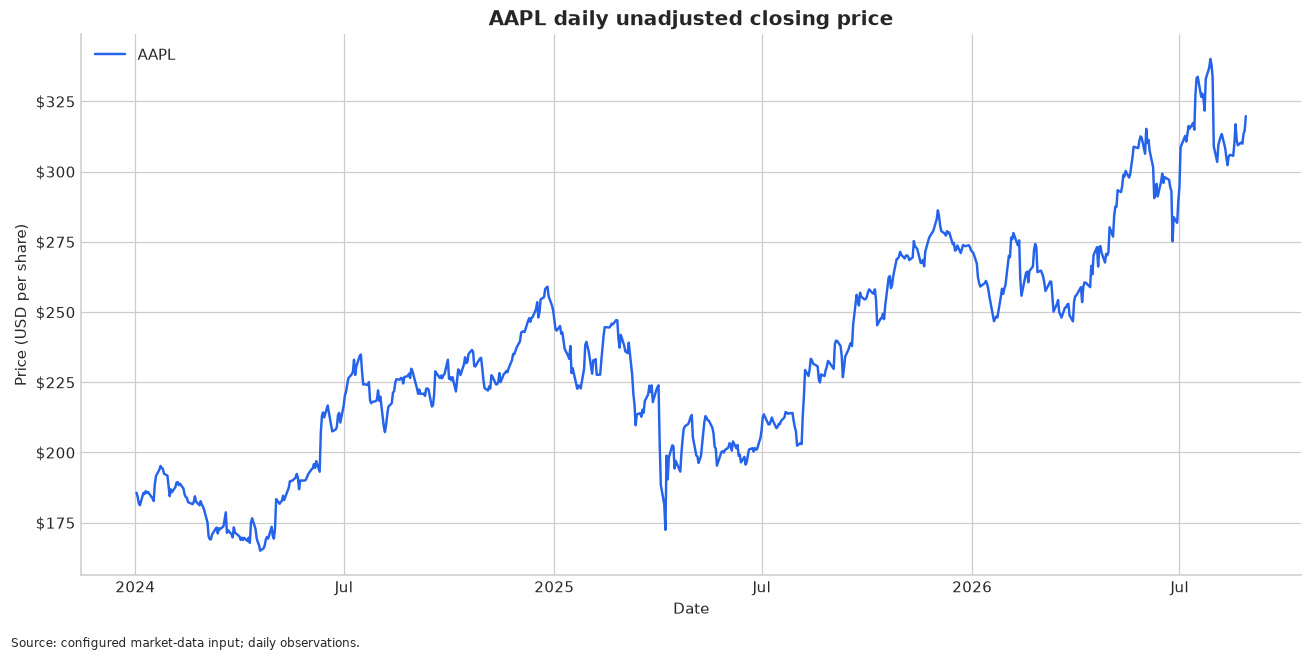

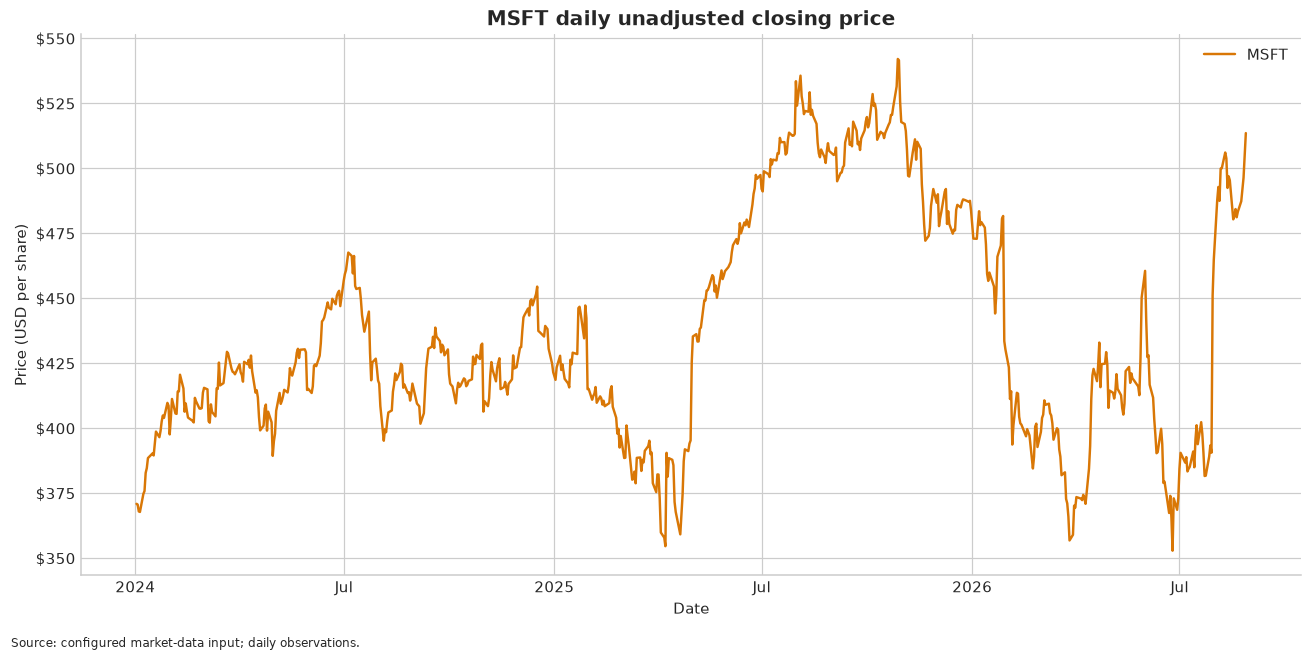

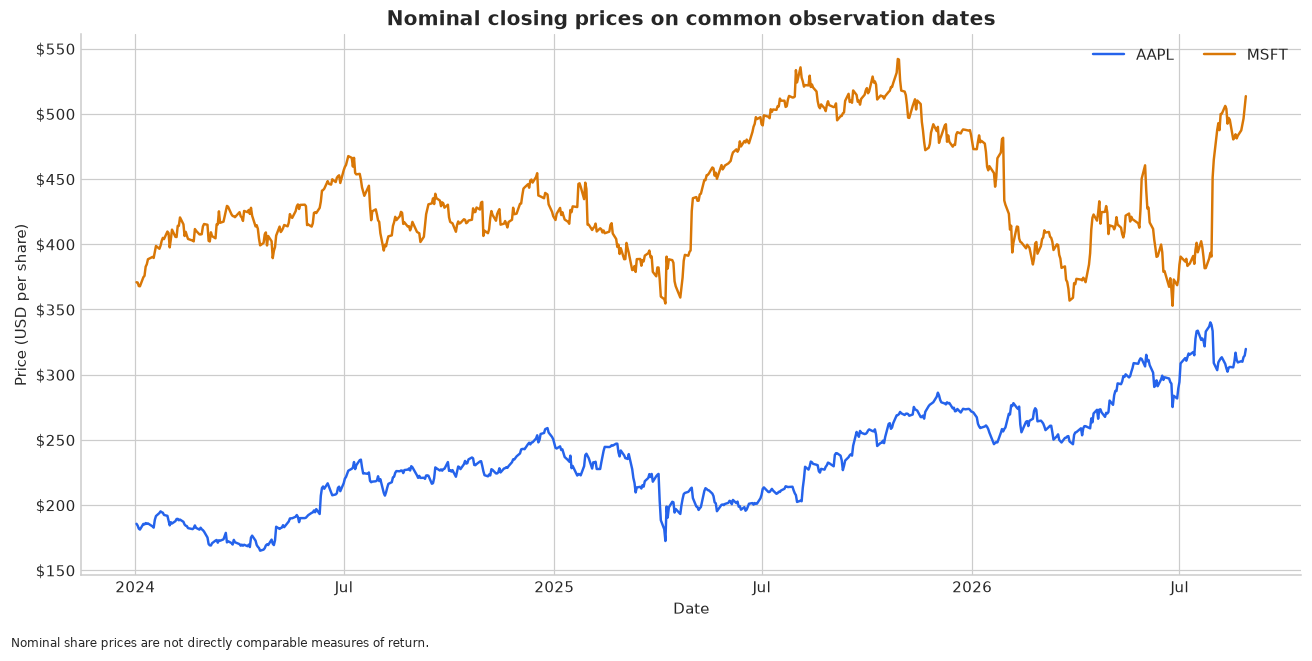

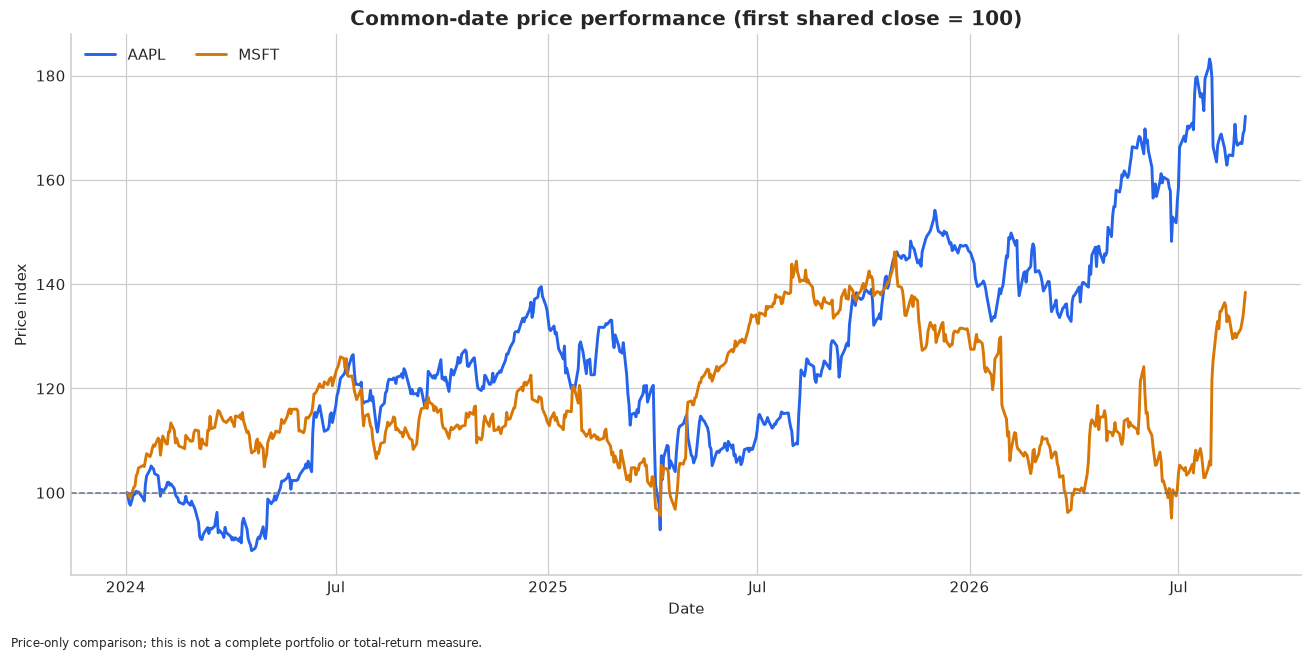

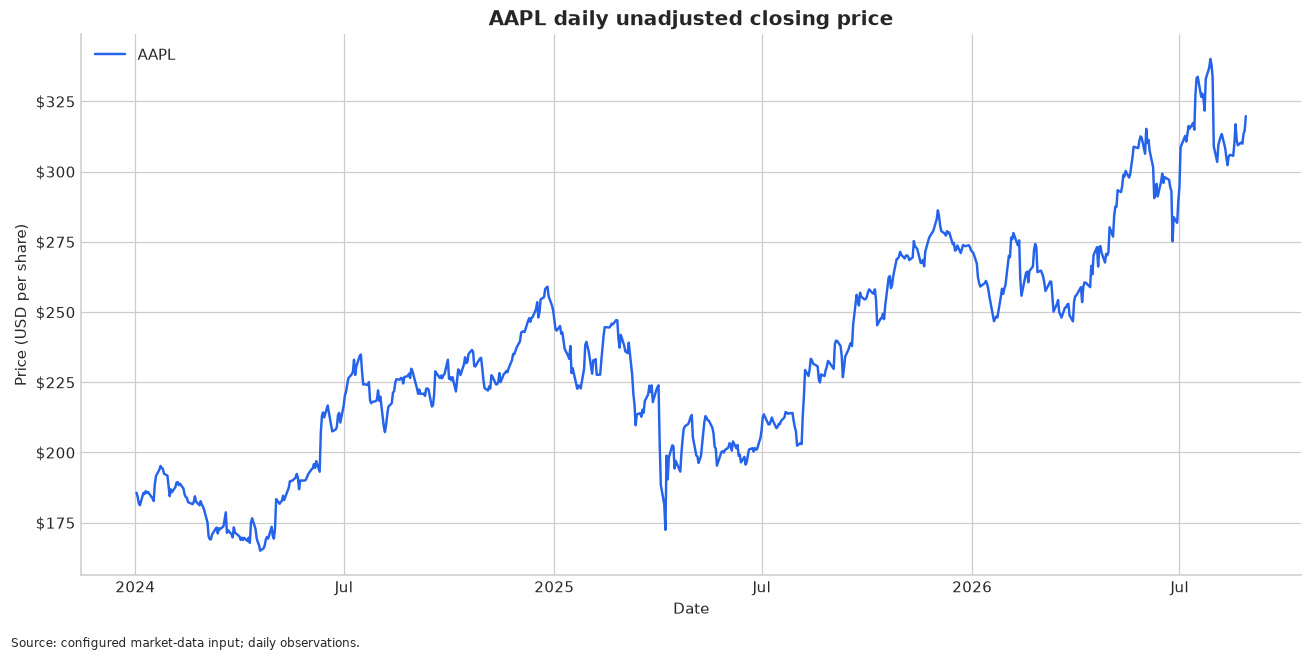

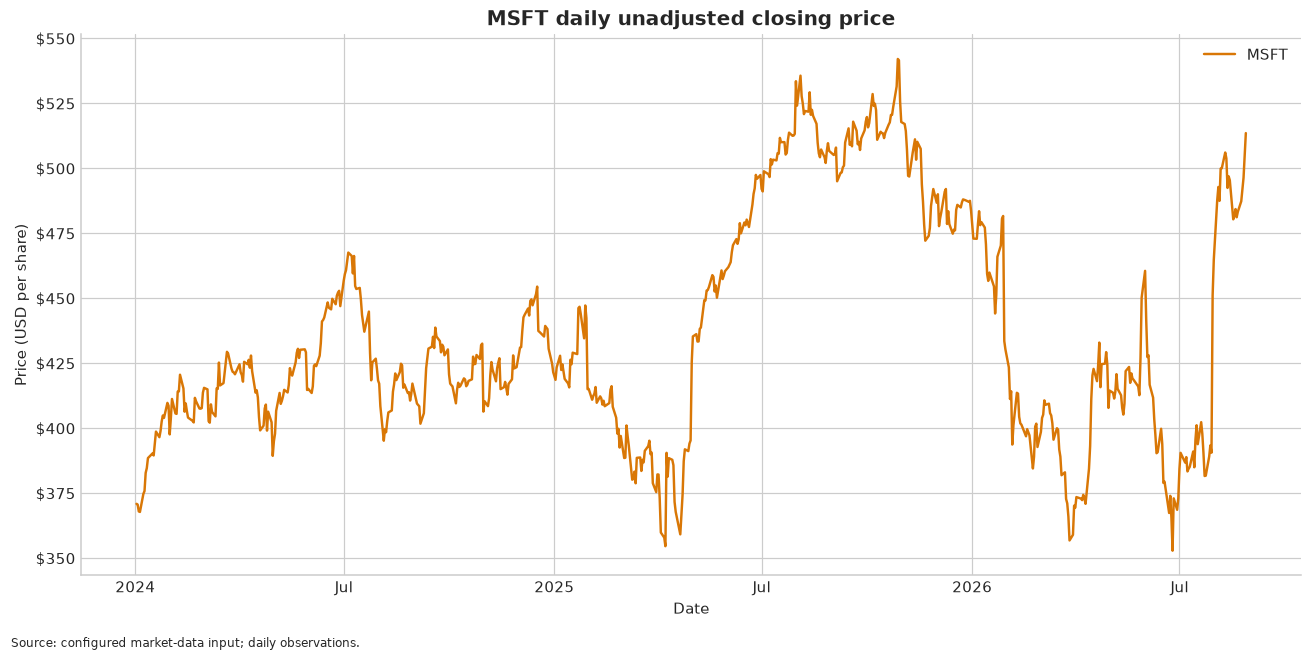

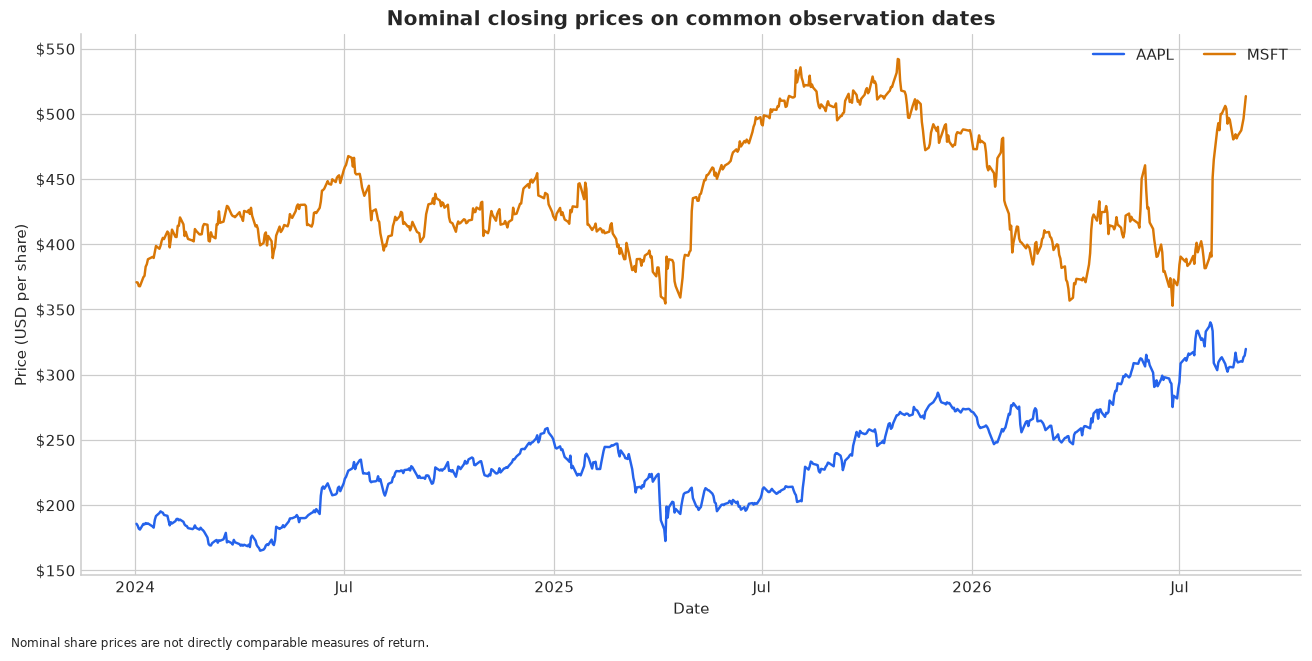

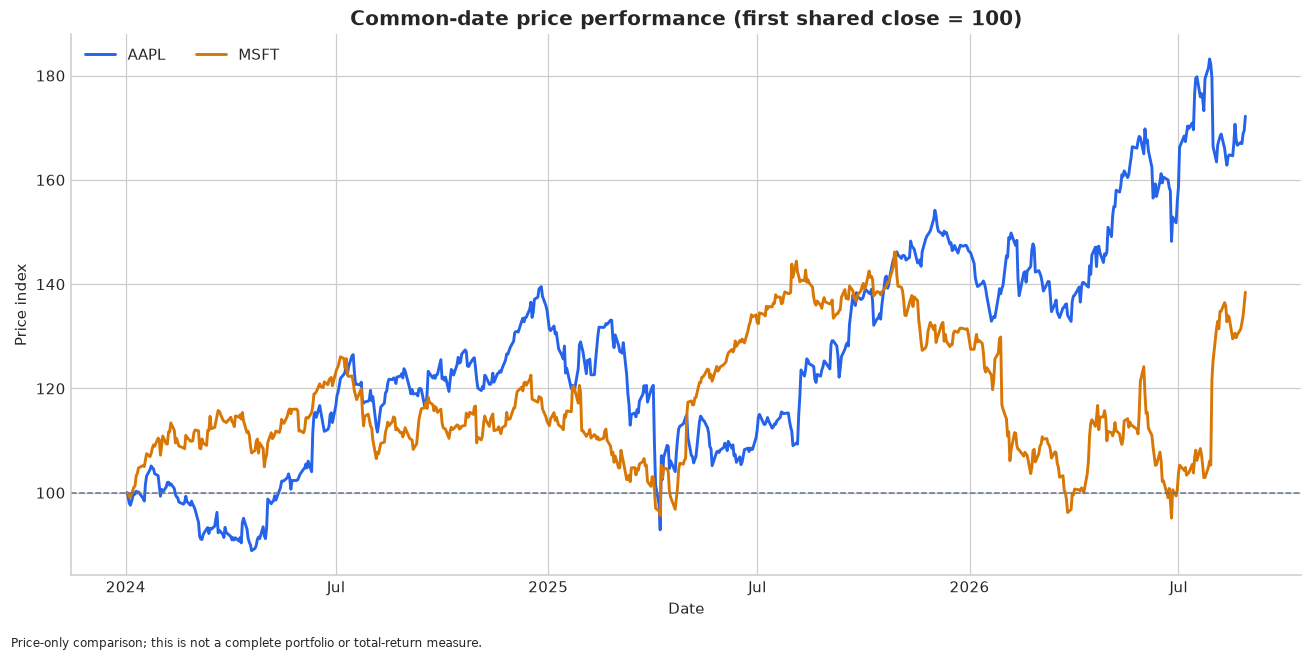

In [6]:
figures = {}
individual_figures = plot_individual_prices(
    data, price_column=config.price_field, price_basis=config.price_basis
)
for ticker, figure in individual_figures.items():
    figures[f"{ticker.lower()}_daily_close"] = figure
    display(figure)

figures["comparative_nominal_close"] = plot_comparative_prices(
    data, price_column=config.price_field
)
display(figures["comparative_nominal_close"])

figures["normalized_price_performance"] = plot_normalized_performance(
    data, price_column=config.price_field
)
display(figures["normalized_price_performance"])

## Section 7 — Weekly resampling

`.resample("W-FRI")` creates Friday-ending periods. Open is the first valid open, high is the maximum high, low is the minimum low, close is the **last available close** (not a mean), and volume is summed. Partial boundary weeks are retained consistently and may contain fewer sessions.

In [7]:
weekly = {
    ticker: resample_ohlcv(frame, config.weekly_rule, include_partial_periods=True)
    for ticker, frame in data.items()
}
display(
    pd.concat(
        {ticker: frame.tail(4) for ticker, frame in weekly.items()}, names=["Ticker", "Week ending"]
    ).round(2)
)
print({ticker: len(frame) for ticker, frame in weekly.items()})

Open    High     Low   Close     Volume  Adj Close
Ticker Week ending                                                      
AAPL   2026-08-07   309.58  316.29  301.32  313.33  273068900     313.06
       2026-08-14   306.83  309.97  300.57  305.93  192525700     305.93
       2026-08-21   306.21  320.28  302.94  309.35  229935400     309.35
       2026-08-28   311.47  322.37  308.21  319.70  165636500     319.70
MSFT   2026-08-07   476.13  505.18  475.00  499.99  215894200     499.05
       2026-08-14   503.44  513.73  491.52  495.40  122514000     494.47
       2026-08-21   490.14  492.66  477.15  483.24  116216900     483.24
       2026-08-28   483.21  517.78  481.86  513.53  115404800     513.53

{'AAPL': 139, 'MSFT': 139}


## Section 8 — Monthly resampling

`.resample("ME")` uses Pandas' documented month-end alias. The OHLCV rules are identical to weekly aggregation. Monthly output contains fewer plotted points and suppresses day-to-day visual noise, but it does not erase the underlying daily data or average closing prices.

Open    High     Low   Close      Volume  Adj Close
Ticker Month ending                                                       
AAPL   2026-05-31    278.86  315.00  274.86  312.06   981286400     311.79
       2026-06-30    309.63  317.40  273.75  289.36  1401170100     289.11
       2026-07-31    293.44  344.57  289.20  308.91  1198861200     308.64
       2026-08-31    309.58  322.37  300.57  319.70   861166500     319.70
MSFT   2026-05-31    412.80  450.33  400.88  450.24   698954800     449.39
       2026-06-30    464.84  466.32  349.20  373.02  1017814300     372.32
       2026-07-31    380.83  466.84  373.35  464.72   815118000     463.85
       2026-08-31    476.13  517.78  475.00  513.53   570029900     513.53

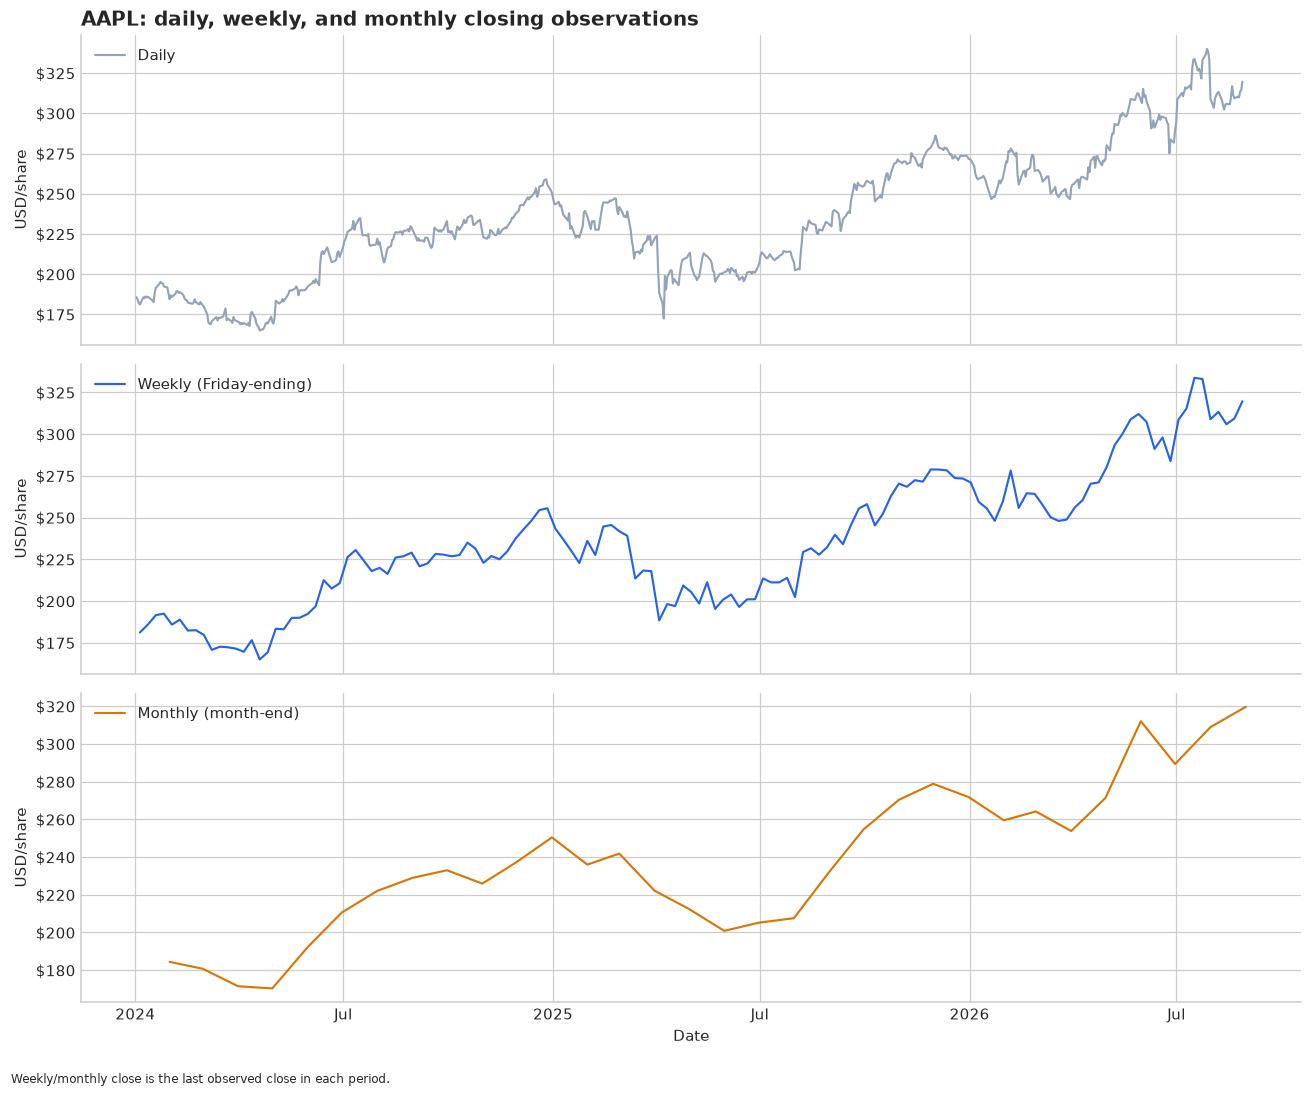

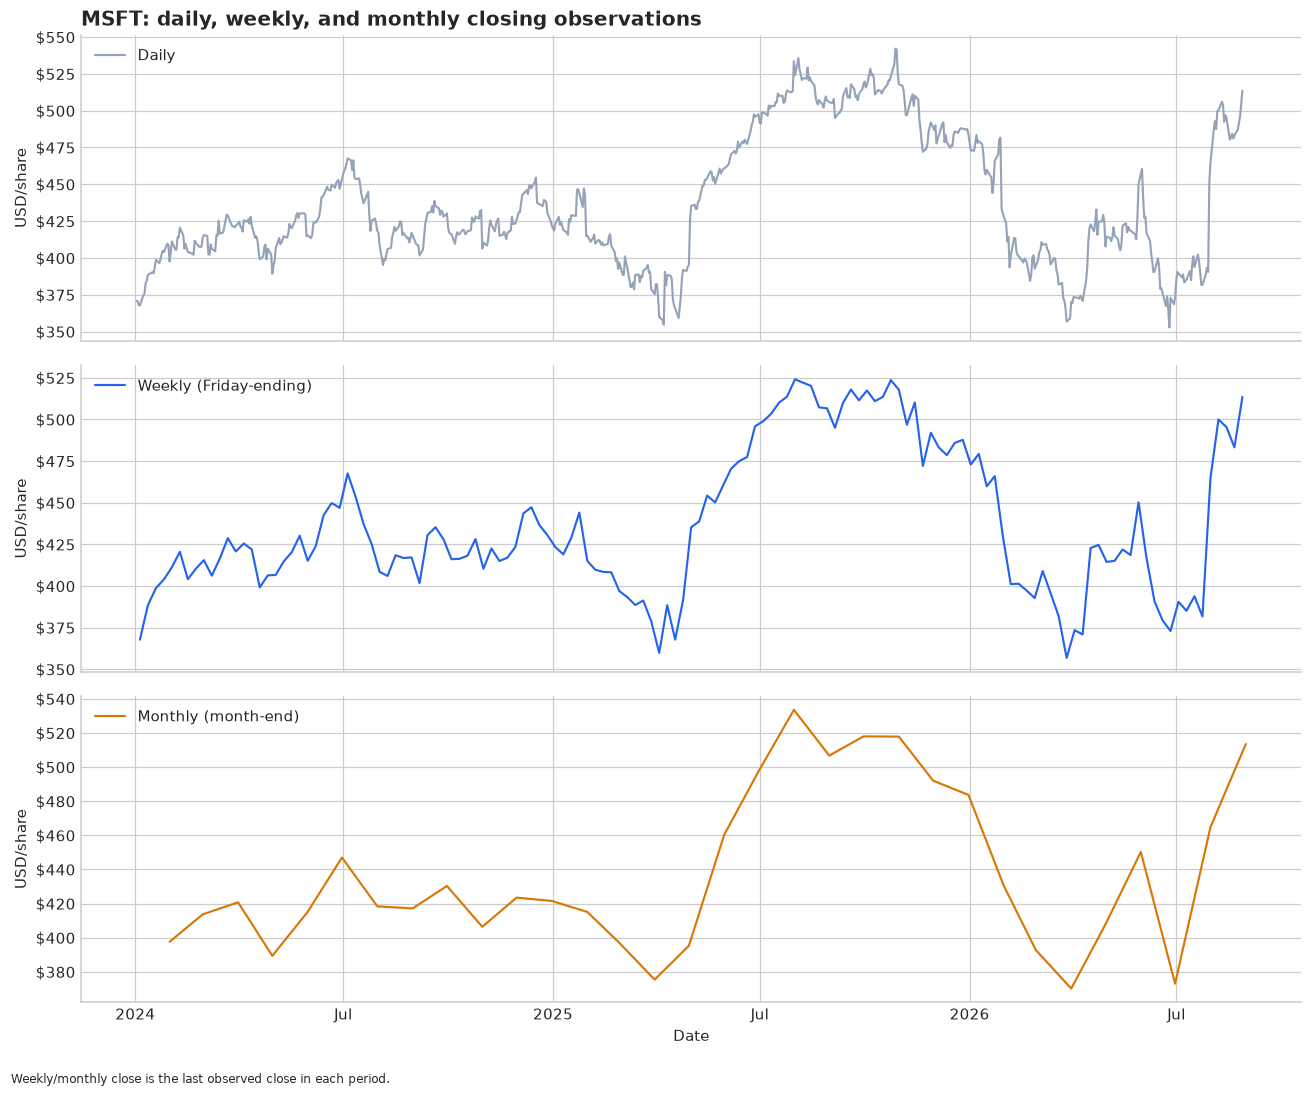

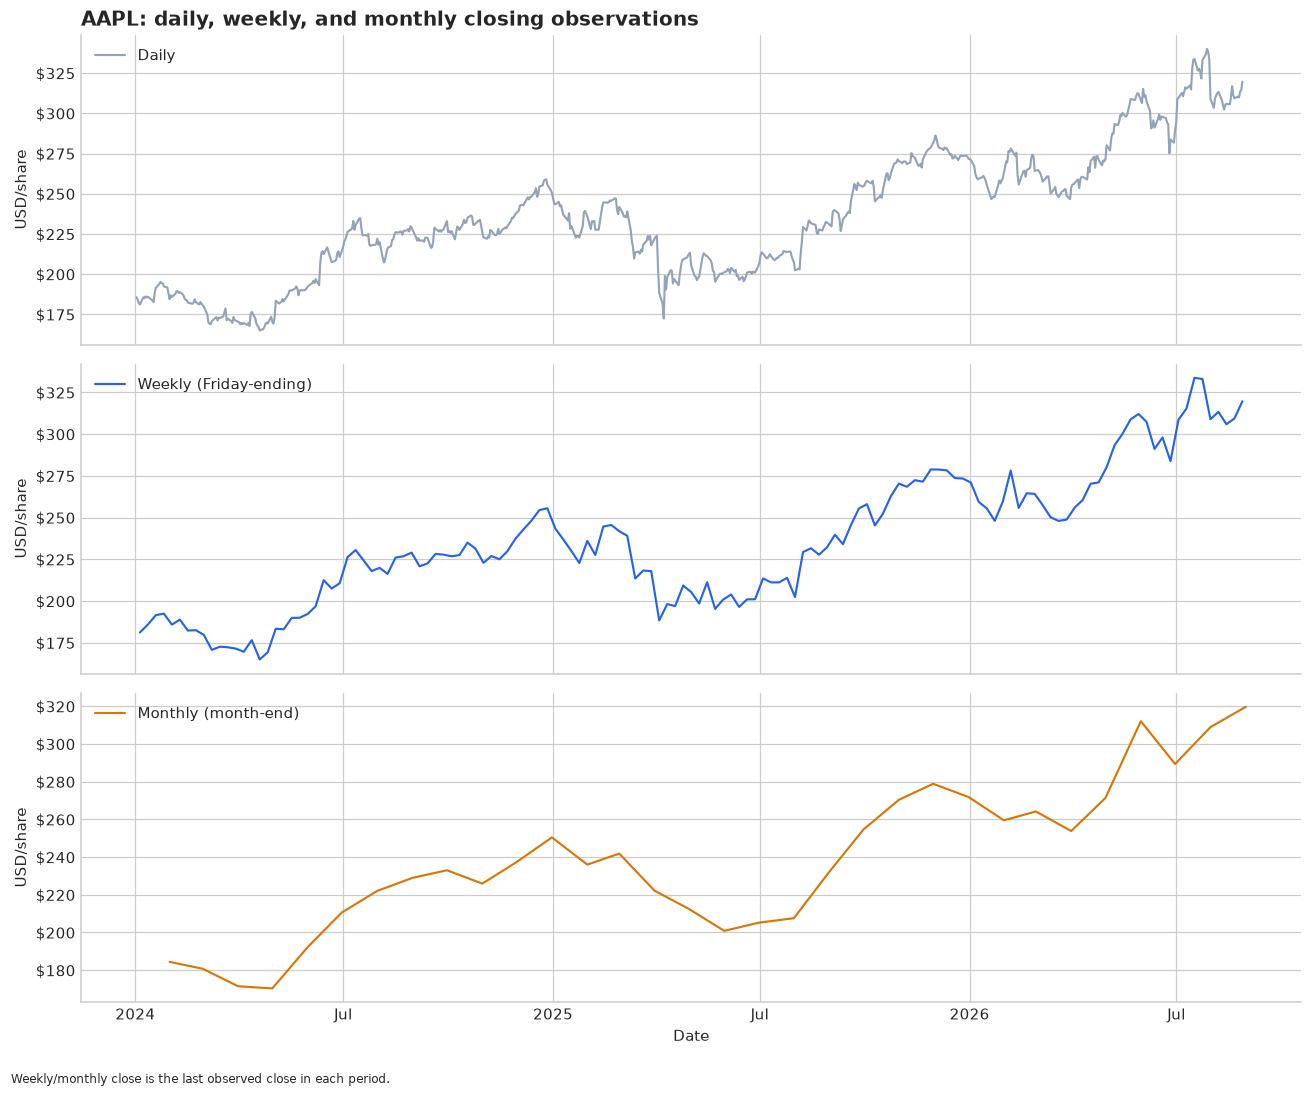

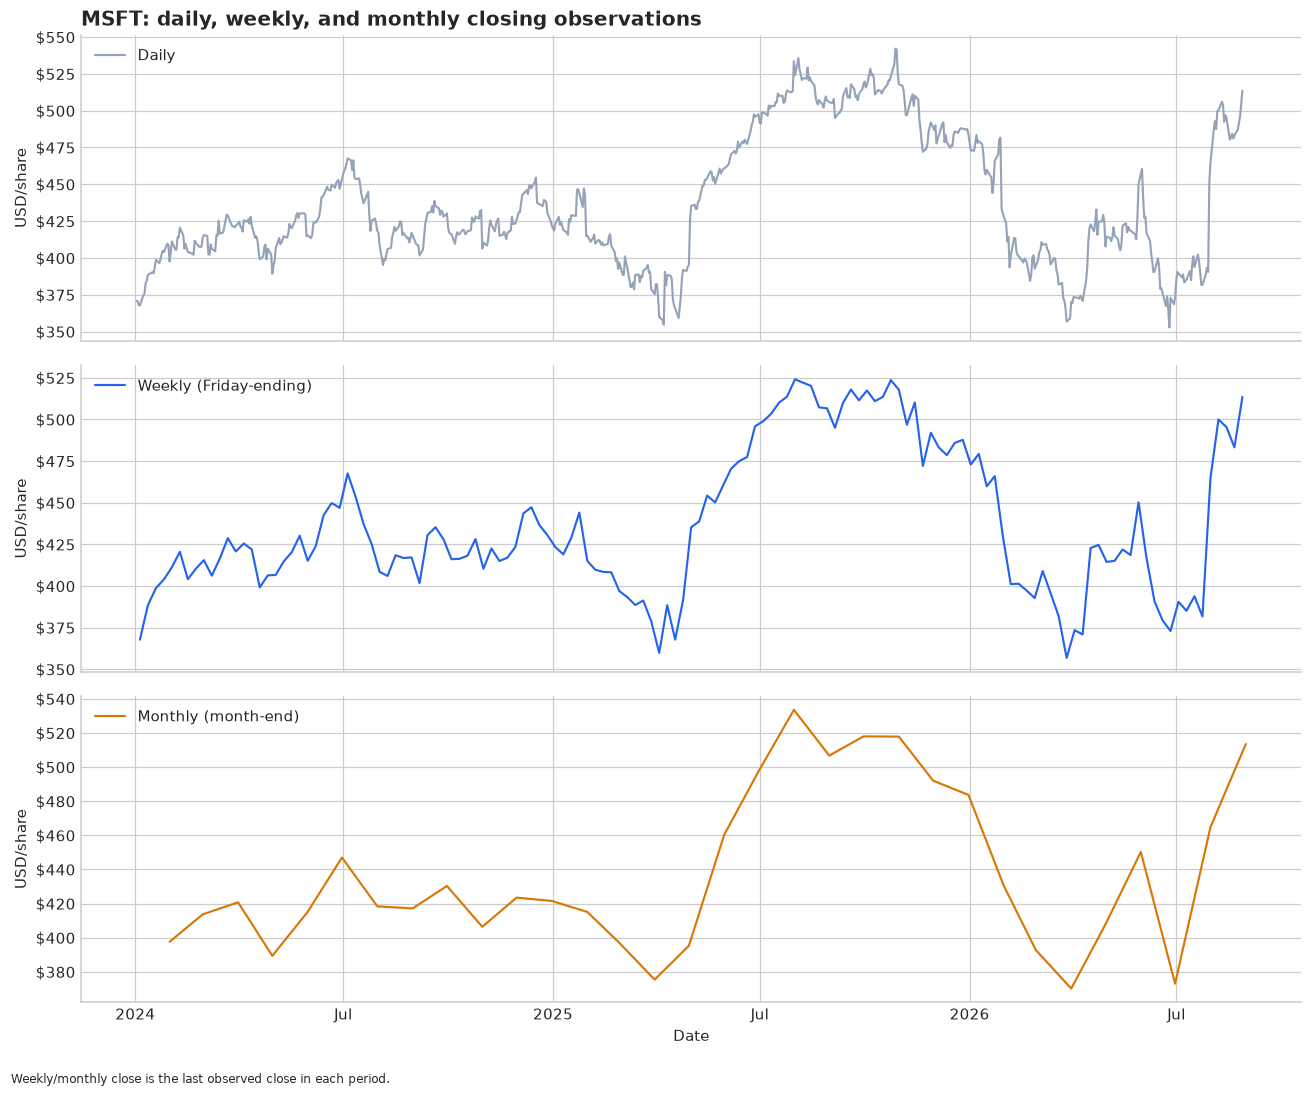

In [8]:
monthly = {
    ticker: resample_ohlcv(frame, config.monthly_rule, include_partial_periods=True)
    for ticker, frame in data.items()
}
display(
    pd.concat(
        {ticker: frame.tail(4) for ticker, frame in monthly.items()},
        names=["Ticker", "Month ending"],
    ).round(2)
)

for ticker in config.tickers:
    figure = plot_frequency_comparison(
        ticker, data[ticker], weekly[ticker], monthly[ticker], price_column=config.price_field
    )
    figures[f"{ticker.lower()}_frequency_comparison"] = figure
    display(figure)

## Section 9 — Moving-average analysis

A rolling window uses the current and preceding observations only. Here, 20 sessions approximate one trading month and 200 sessions describe a longer historical trend. `min_periods` equals each full window, so warm-up values remain missing rather than being fabricated. Both lines are lagging summaries—not guaranteed predictors or standalone trading signals.

,SMA_20 available,SMA_200 available
AAPL,648,468
MSFT,648,468


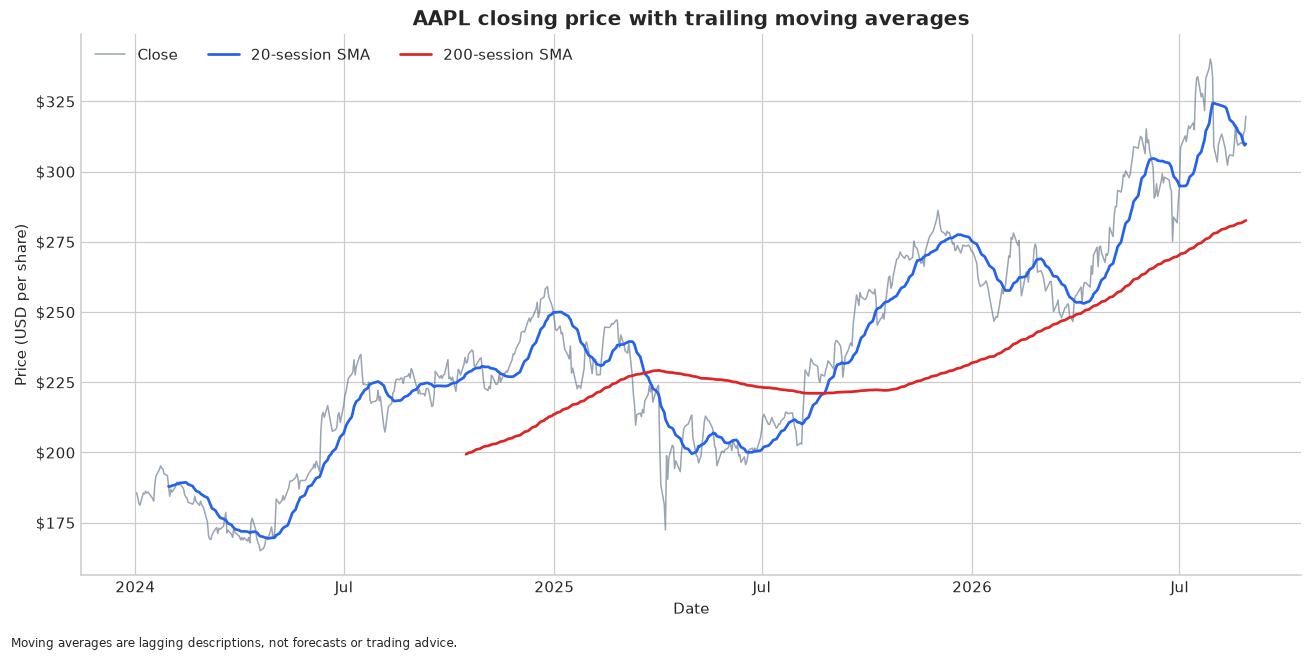

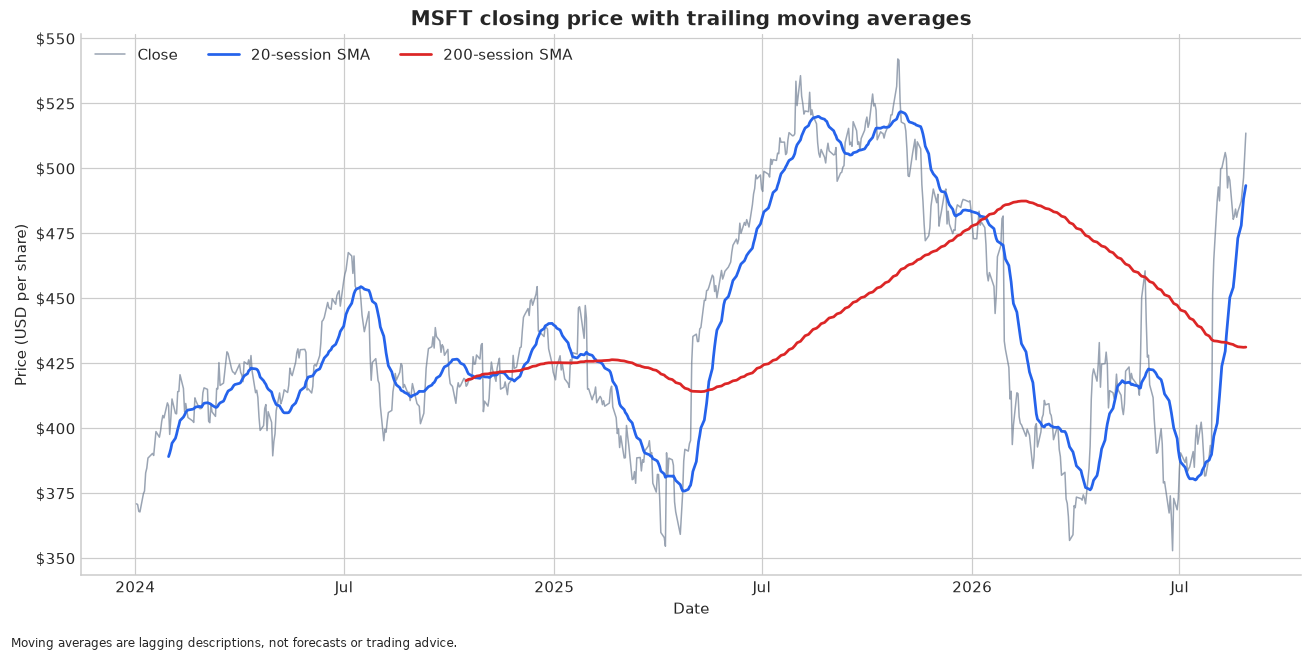

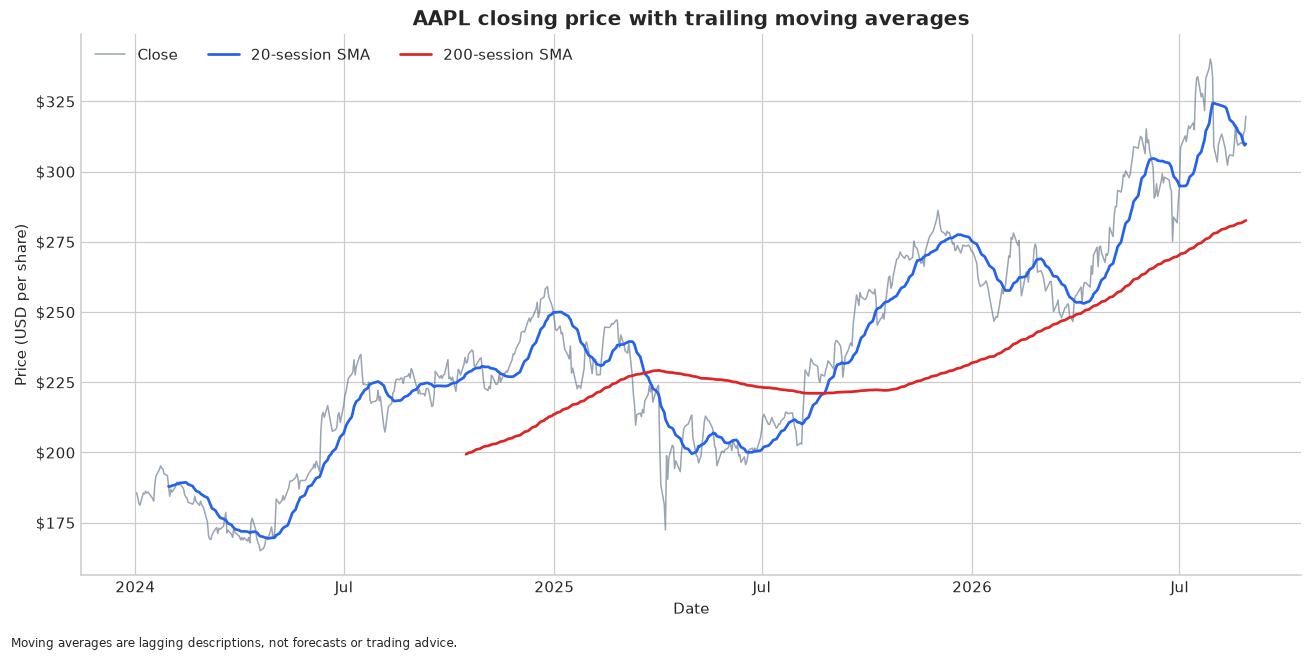

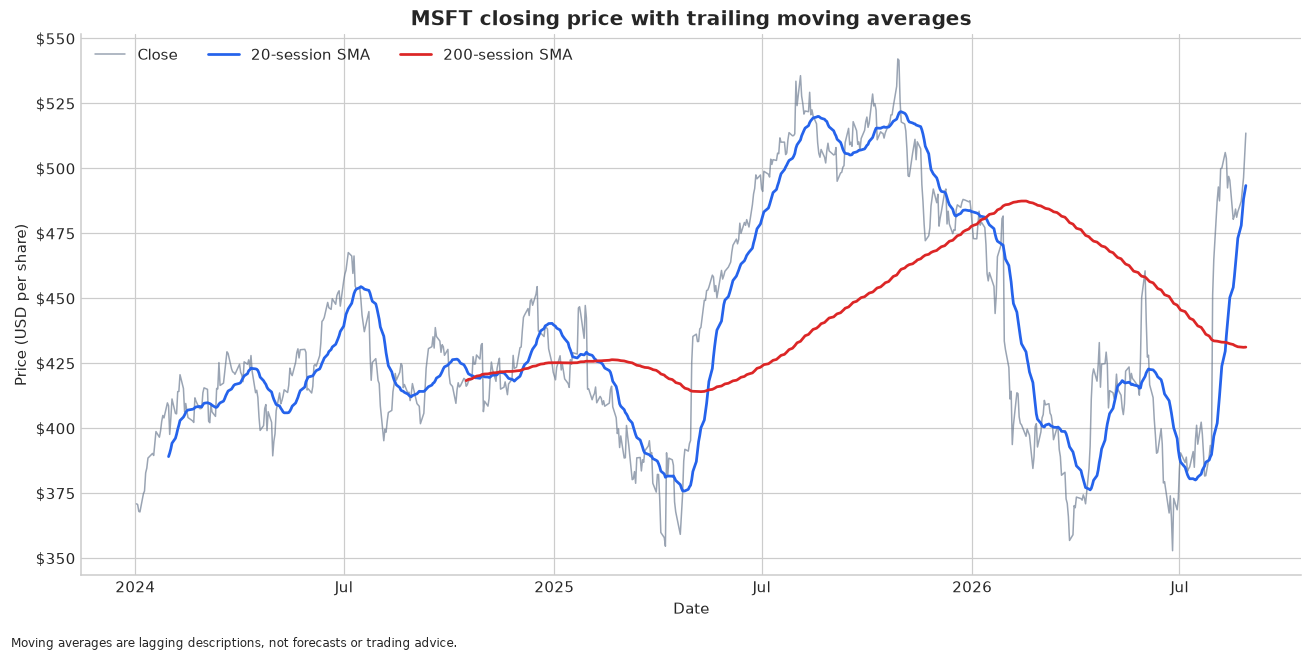

In [9]:
moving_averages = {
    ticker: calculate_moving_averages(
        frame,
        price_column=config.price_field,
        windows=config.moving_average_windows,
    )
    for ticker, frame in data.items()
}

warmup_table = pd.DataFrame(
    {
        ticker: {
            f"SMA_{window} available": int(frame[f"SMA_{window}"].notna().sum())
            for window in config.moving_average_windows
        }
        for ticker, frame in moving_averages.items()
    }
).T
display(warmup_table)

for ticker, frame in moving_averages.items():
    figure = plot_moving_averages(
        ticker, frame, price_column=config.price_field, windows=config.moving_average_windows
    )
    figures[f"{ticker.lower()}_moving_averages"] = figure
    display(figure)

## Section 10 — Trading-volume comparison

The top panel preserves daily share volume (faint lines) and adds a readable 20-session mean. The middle panel divides each company's volume by its own sample mean, measuring relative activity rather than raw shares. The bottom panel compares weekly summed volume. Share count is not company size, investor intent, or liquidity quality. Approximate dollar turnover (`Close × Volume`) appears in the metrics table and is labeled as an approximation.

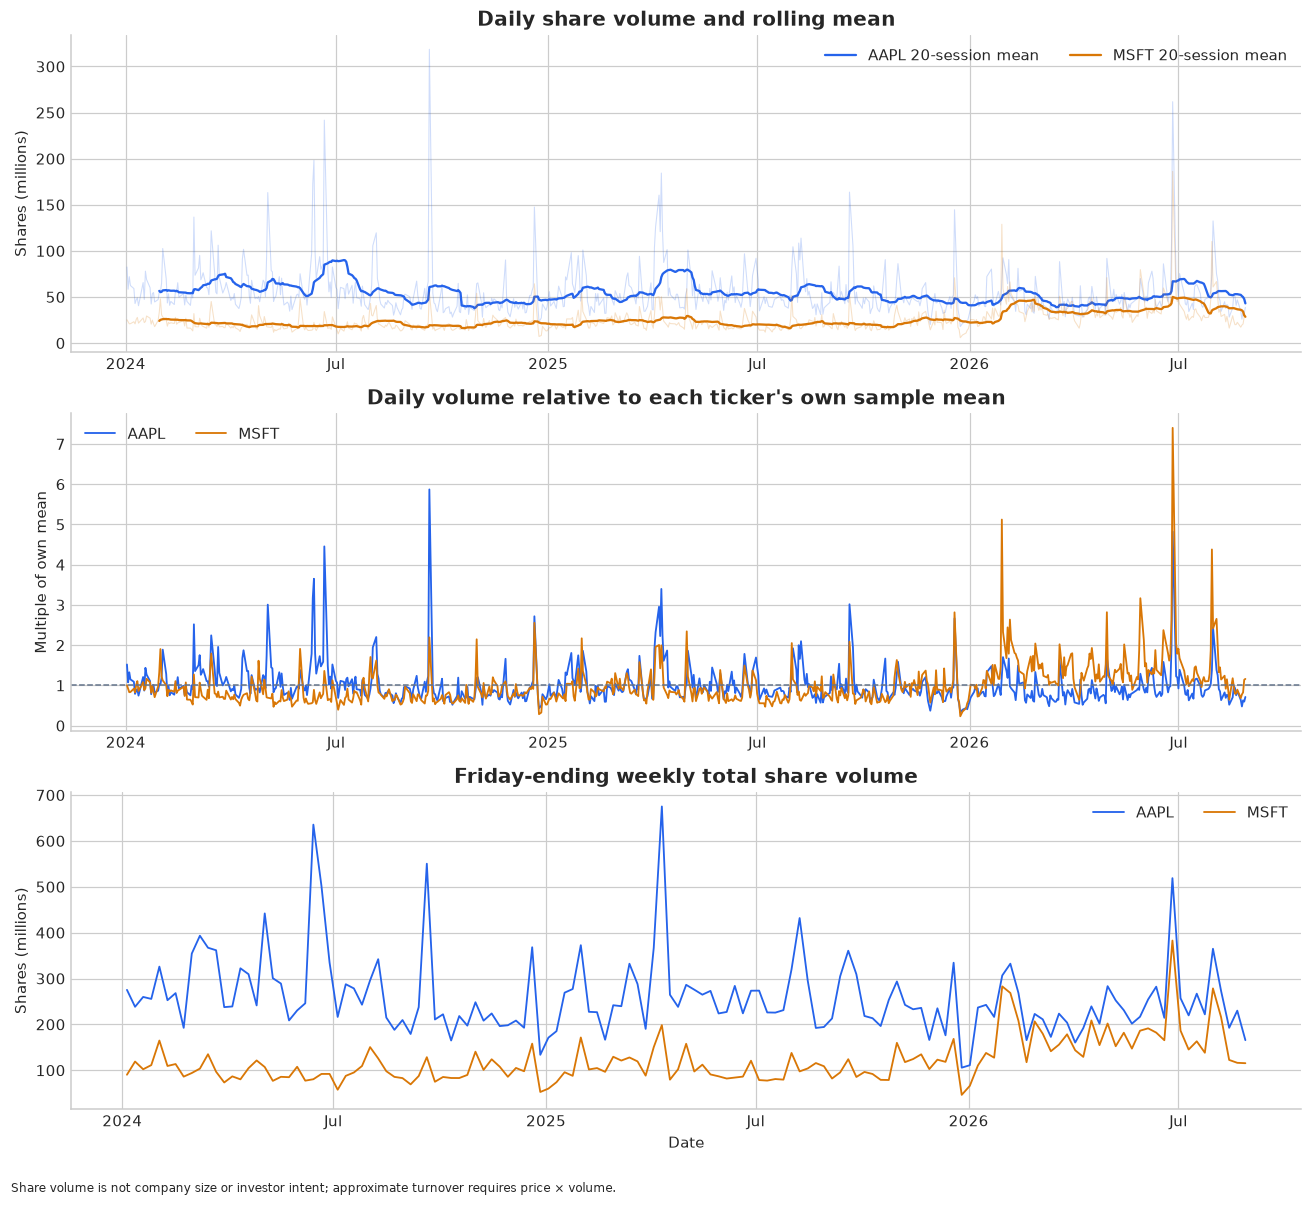

,Mean daily shares,Median daily shares,Total observed shares,Approx. mean daily turnover (USD)
AAPL,"54,293,628","48,073,400","36,213,849,800","12,598,379,334"
MSFT,"25,163,769","21,502,200","16,784,233,800","10,863,536,456"


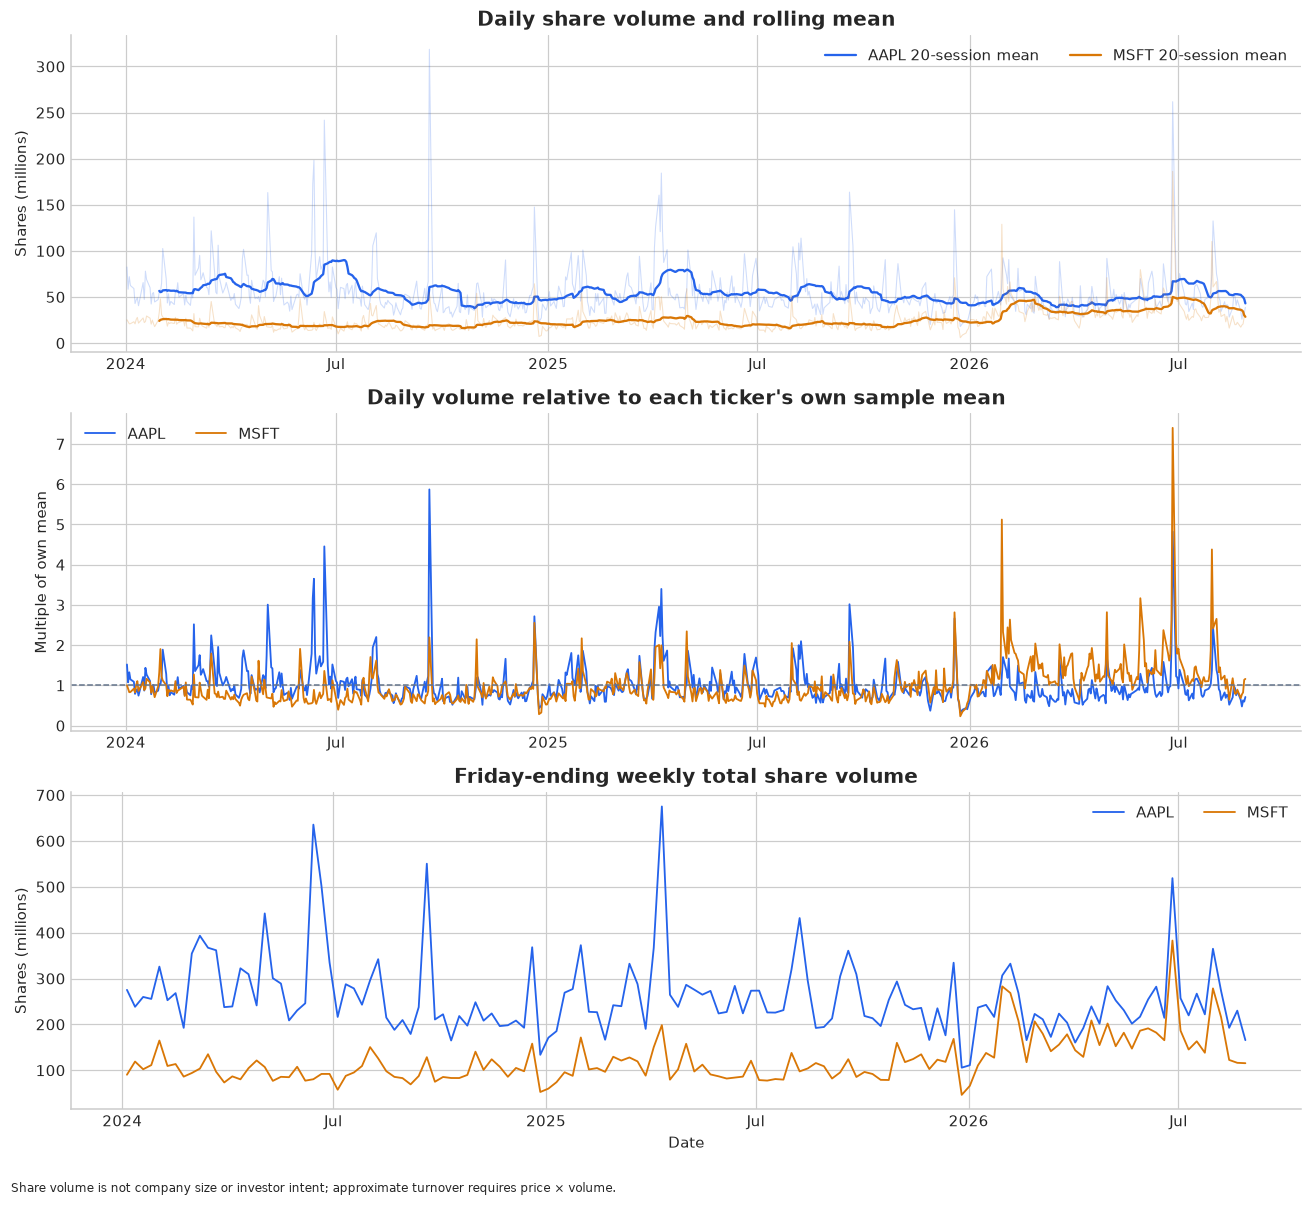

In [10]:
figures["volume_comparison"] = plot_volume_comparison(
    data, weekly, rolling_window=config.volatility_window
)
display(figures["volume_comparison"])

volume_summary = pd.DataFrame(
    {
        ticker: {
            "Mean daily shares": frame["Volume"].mean(),
            "Median daily shares": frame["Volume"].median(),
            "Total observed shares": frame["Volume"].sum(),
            "Approx. mean daily turnover (USD)": (
                frame[config.price_field] * frame["Volume"]
            ).mean(),
        }
        for ticker, frame in data.items()
    }
).T
display(volume_summary.style.format("{:,.0f}"))

## Section 11 — Returns and performance metrics

Daily percentage return is `(price_t / price_(t-1)) - 1`; the first result remains missing because no prior observation exists. Cumulative performance uses the common first date as index 100. Annualized volatility is daily return standard deviation multiplied by √252. These describe this historical sample and do not forecast future outcomes.

,AAPL,MSFT
Date,,
2024-01-02,NaN,NaN
2024-01-03,-0.007488,-0.000728
2024-01-04,-0.012700,-0.007178
2024-01-05,-0.004013,-0.000516
2024-01-08,0.024175,0.018872


,Start date,End date,Observations,First close,Last close,Absolute price change,Percentage price change,CAGR,Mean daily return,Median daily return,Daily return std,Annualized volatility,Maximum drawdown,Minimum close,Maximum close,Mean daily volume,Median daily volume,Total observed volume,Approx. mean daily turnover
Ticker,,,,,,,,,,,,,,,,,,,
AAPL,2024-01-02 00:00:00,2026-08-28 00:00:00,667,$185.64,$319.70,$134.06,72.2%,22.7%,0.097%,0.128%,1.74%,27.7%,-33.4%,$165.00,$340.08,"54,293,628","48,073,400","36,213,849,800","$12,598,379,334"
MSFT,2024-01-02 00:00:00,2026-08-28 00:00:00,667,$370.87,$513.53,$142.66,38.5%,13.1%,0.063%,0.077%,1.69%,26.9%,-34.9%,$352.83,$542.07,"25,163,769","21,502,200","16,784,233,800","$10,863,536,456"


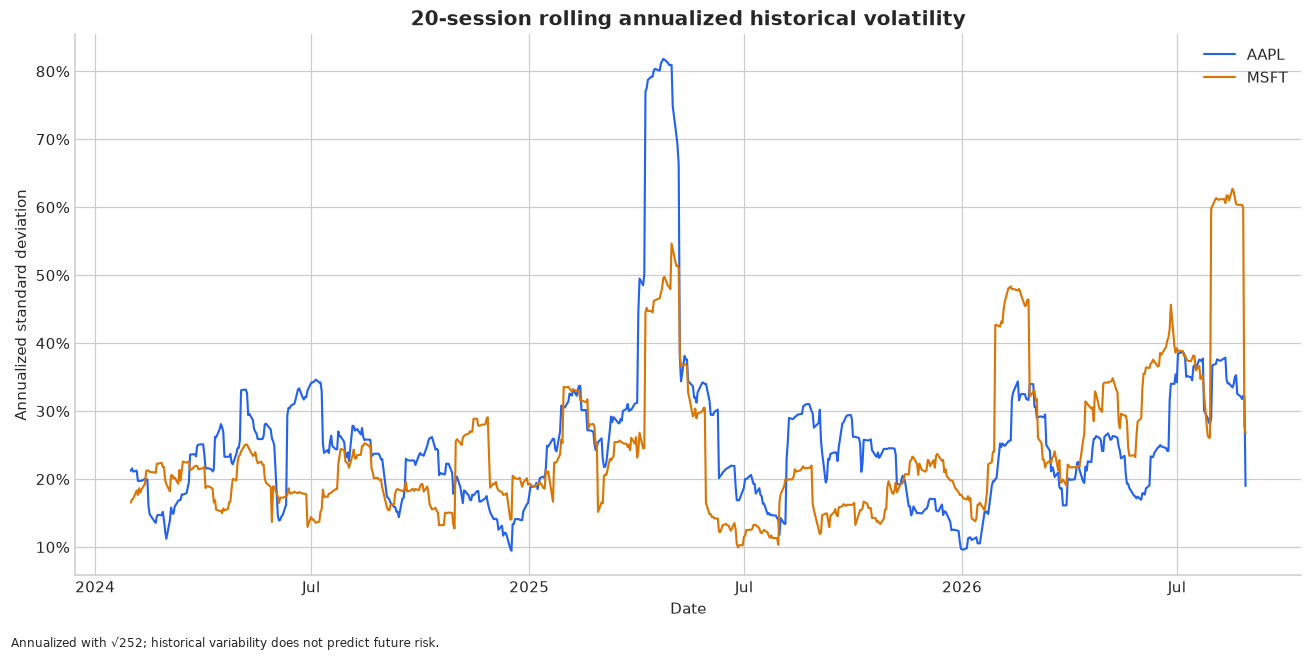

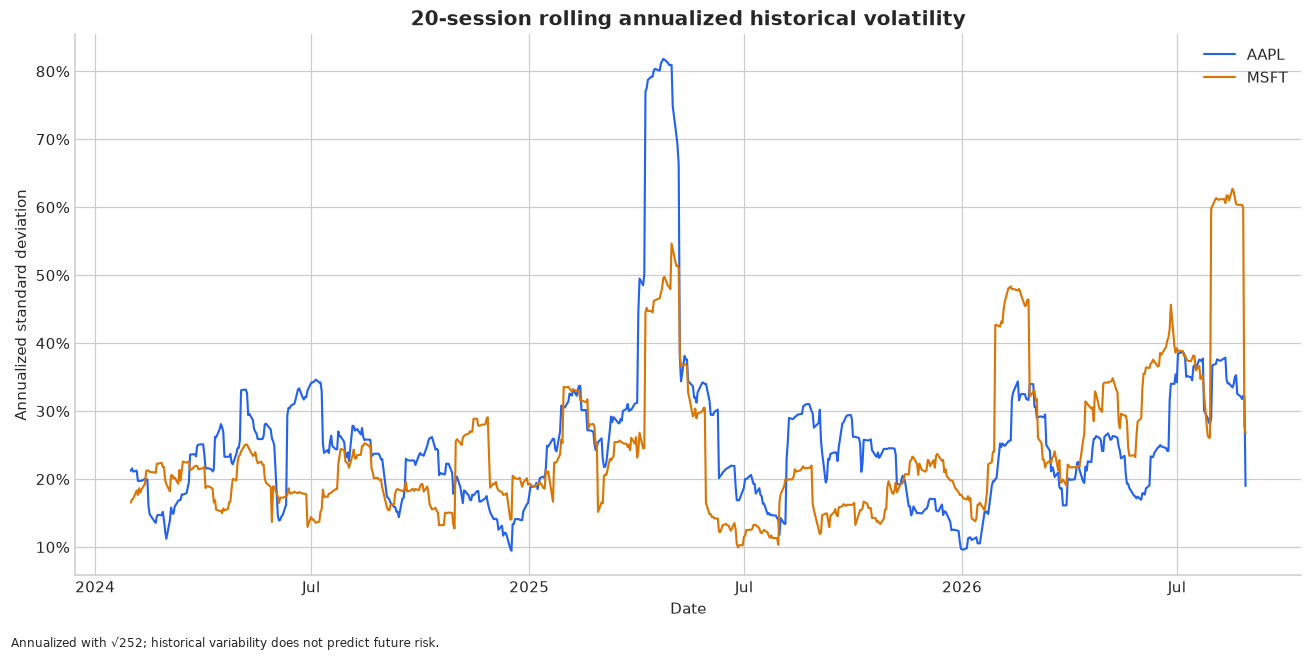

In [11]:
aligned_prices = align_common_dates(data, column=config.price_field)
daily_returns = aligned_prices.pct_change(fill_method=None)
normalized_performance = calculate_cumulative_performance(aligned_prices)
rolling_volatility = {
    ticker: calculate_rolling_volatility(
        calculate_daily_returns(frame[config.price_field]),
        window=config.volatility_window,
        annualization_factor=config.annualization_factor,
    )
    for ticker, frame in data.items()
}
summary = create_summary_table(
    data,
    price_column=config.price_field,
    annualization_factor=config.annualization_factor,
)

display(daily_returns.head())
display(
    summary.style.format(
        {
            "First close": "${:,.2f}",
            "Last close": "${:,.2f}",
            "Absolute price change": "${:,.2f}",
            "Percentage price change": "{:.1%}",
            "CAGR": "{:.1%}",
            "Mean daily return": "{:.3%}",
            "Median daily return": "{:.3%}",
            "Daily return std": "{:.2%}",
            "Annualized volatility": "{:.1%}",
            "Maximum drawdown": "{:.1%}",
            "Minimum close": "${:,.2f}",
            "Maximum close": "${:,.2f}",
            "Mean daily volume": "{:,.0f}",
            "Median daily volume": "{:,.0f}",
            "Total observed volume": "{:,.0f}",
            "Approx. mean daily turnover": "${:,.0f}",
        }
    )
)

figures["rolling_historical_volatility"] = plot_rolling_volatility(
    rolling_volatility, window=config.volatility_window
)
display(figures["rolling_historical_volatility"])

## Section 12 — Advanced analysis: drawdown and return correlation

Drawdown measures each close relative to its running historical peak; maximum drawdown depends on the selected window. Pearson correlation is calculated from daily percentage returns on common dates. Correlation measures historical linear association—not causation—and can change.

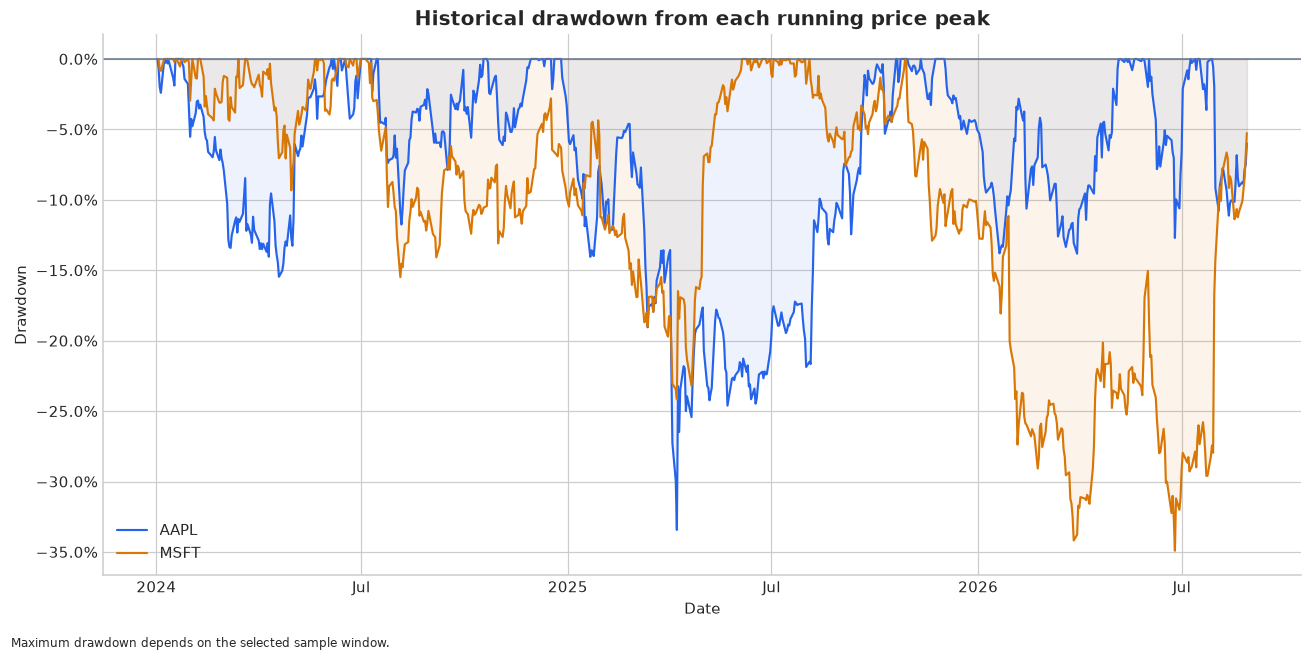

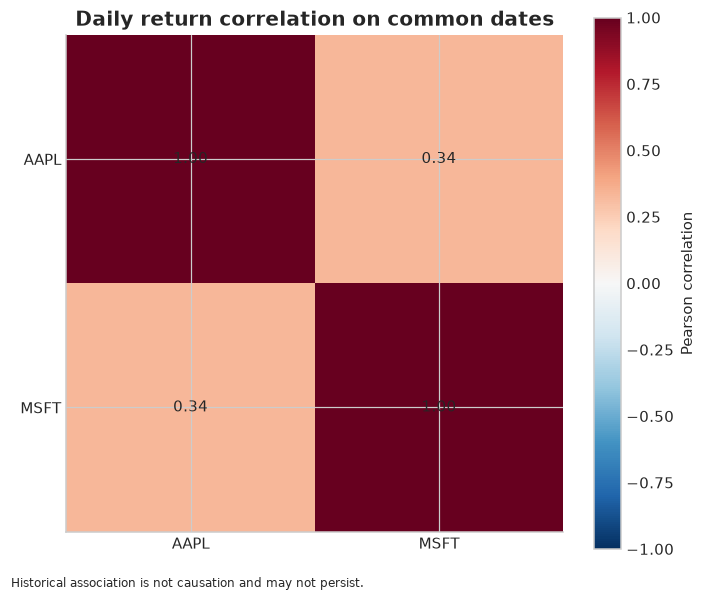

,AAPL,MSFT
AAPL,1.000,0.335
MSFT,0.335,1.000


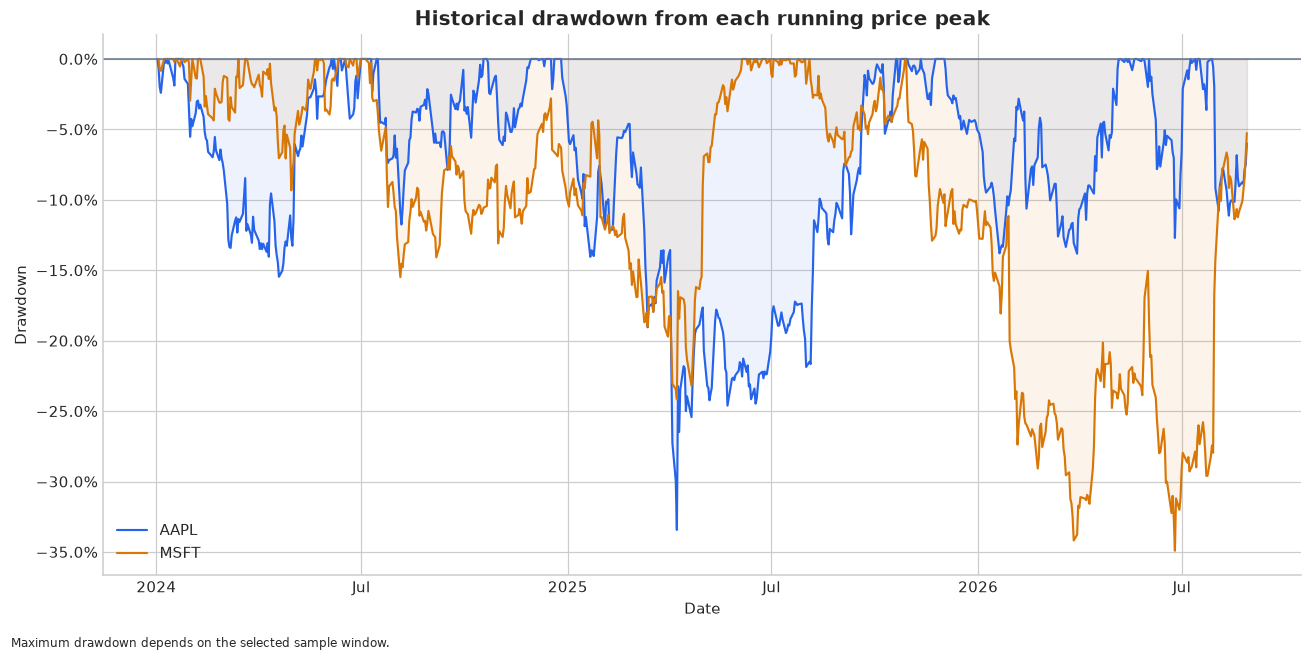

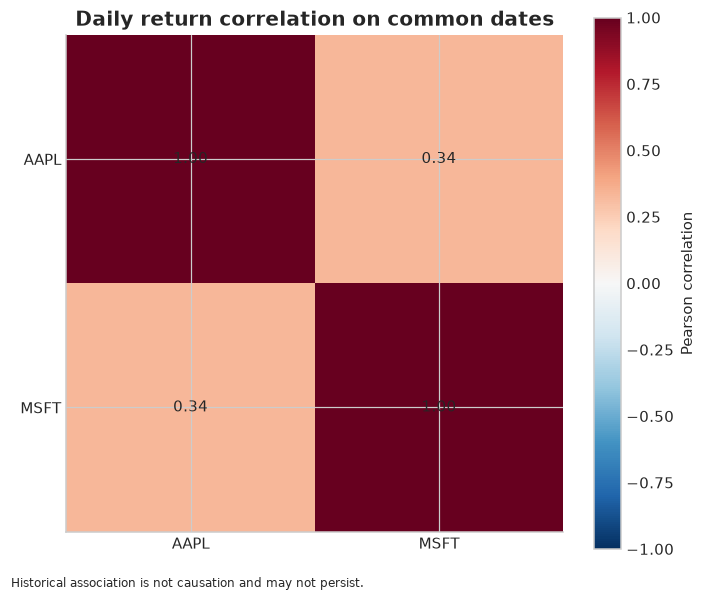

In [12]:
drawdowns = {
    ticker: calculate_drawdown(frame[config.price_field]) for ticker, frame in data.items()
}
return_correlation = calculate_return_correlation(data, price_column=config.price_field)

figures["historical_drawdowns"] = plot_drawdowns(drawdowns)
display(figures["historical_drawdowns"])
figures["daily_return_correlation"] = plot_return_correlation(return_correlation)
display(figures["daily_return_correlation"])
display(return_correlation.style.format("{:.3f}"))

## Section 13 — Findings and interpretation

The statements below are generated from the loaded observations. Labels distinguish observed relationships, calculated statistics, limitations, and explanations that the data cannot establish. No news event or causal story is invented.

In [13]:
findings = generate_findings(summary, moving_averages, return_correlation)
display(
    Markdown("\n".join(f"{index}. {finding}" for index, finding in enumerate(findings, start=1)))
)

1. Calculated result: AAPL had the largest price-only change in the selected window (72.2%).
2. Calculated result: AAPL had the greatest annualized historical daily-return variability (27.7%, using √252).
3. Observed fact: AAPL had the higher mean share volume in this sample (54.3 million shares/day). This does not establish company size, liquidity quality, or investor intent.
4. Observed relationship: on 2026-08-28, AAPL's close was above its 200-session moving average. This is descriptive, not a signal.
5. Observed relationship: on 2026-08-28, MSFT's close was above its 200-session moving average. This is descriptive, not a signal.
6. Calculated result: AAPL and MSFT daily returns had a 0.34 Pearson correlation on common dates. Historical correlation is association, not causation, and can change.
7. Methodological observation: weekly and monthly closes use the last available close in each period, reducing plotted point density without averaging closing prices.
8. Unresolved explanation: prices and volumes alone cannot establish why any observed move occurred; no news or causal narrative is inferred.

## Section 14 — Export results

Exports are derived into separate `data/processed`, `outputs/tables`, `outputs/figures`, and `outputs/reports` locations. Raw inputs are never overwritten. Filenames include ticker symbols and requested dates through `config.run_label`.

In [14]:
figure_dir = config.output_dir / "figures"
figure_paths = {}
for name, figure in figures.items():
    path = figure_dir / f"{config.run_label}_{name}.png"
    figure_paths[name] = save_figure(figure, path, dpi=config.figure_dpi)

exported_tables = export_analysis_tables(
    data=data,
    weekly=weekly,
    monthly=monthly,
    moving_averages=moving_averages,
    summary=summary,
    normalized_performance=normalized_performance,
    correlation=return_correlation,
    output_dir=config.output_dir,
    processed_dir=config.processed_dir,
    run_label=config.run_label,
)
report_path = write_markdown_report(
    config.output_dir / "reports" / f"{config.run_label}_analysis_report.md",
    title="Stock Price Analysis — Comparative Time-Series Analytics",
    summary=summary,
    findings=findings,
    metadata=download_result.metadata,
    price_basis=config.price_basis,
    figure_paths=[path.relative_to(PROJECT_ROOT) for path in figure_paths.values()],
)

export_manifest = pd.DataFrame(
    [("Figure", name, path) for name, path in figure_paths.items()]
    + [("Table", name, path) for name, path in exported_tables.items()]
    + [("Report", "markdown_report", report_path)],
    columns=["Type", "Artifact", "Path"],
)
display(export_manifest)
print(f"Generated {len(export_manifest)} artifacts without modifying source inputs.")

,Type,Artifact,Path
0,Figure,aapl_daily_close,/home/user/SynapseHub/stock-price-time-series-...
1,Figure,msft_daily_close,/home/user/SynapseHub/stock-price-time-series-...
2,Figure,comparative_nominal_close,/home/user/SynapseHub/stock-price-time-series-...
3,Figure,normalized_price_performance,/home/user/SynapseHub/stock-price-time-series-...
4,Figure,aapl_frequency_comparison,/home/user/SynapseHub/stock-price-time-series-...
5,Figure,msft_frequency_comparison,/home/user/SynapseHub/stock-price-time-series-...
6,Figure,aapl_moving_averages,/home/user/SynapseHub/stock-price-time-series-...
7,Figure,msft_moving_averages,/home/user/SynapseHub/stock-price-time-series-...
8,Figure,volume_comparison,/home/user/SynapseHub/stock-price-time-series-...
9,Figure,rolling_historical_volatility,/home/user/SynapseHub/stock-price-time-series-...


Generated 24 artifacts without modifying source inputs.


## Section 15 — Conclusion

This workflow demonstrates more than plotting: it validates provider structure, records provenance, aligns common dates, preserves non-trading-day gaps, applies correct OHLCV aggregation, prevents look-ahead in rolling calculations, computes price-only performance and risk summaries, and exports auditable artifacts. The charts and report can be regenerated after changing the centralized configuration.

In [15]:
print(f"Analyzed {', '.join(config.tickers)} across {len(common_closes):,} common observations.")
print(f"Weekly rule: {config.weekly_rule}; monthly rule: {config.monthly_rule}.")
print(f"Report: {report_path}")
print(DISCLAIMER)

Analyzed AAPL, MSFT across 667 common observations.
Weekly rule: W-FRI; monthly rule: ME.
Report: /home/user/SynapseHub/stock-price-time-series-analysis/outputs/reports/aapl-msft_20240101_20260901_analysis_report.md
Educational historical analysis only—not financial advice. Past performance, historical volatility, moving averages, drawdowns, and correlations do not predict future results.


## Section 16 — Limitations and further work

- The saved run uses documented archived observations because live Yahoo Finance access was unavailable in the build environment. Live mode and mocked retrieval failures are implemented and tested, but a fresh live response could not be verified here.
- Provider data can be delayed, incomplete, revised, rate-limited, or adjusted differently from another source. The project does not claim real-time completeness.
- `Close` with `auto_adjust=False` is price-only. It is not automatically total shareholder return; distributions require an appropriate adjusted basis and careful interpretation.
- Missing sessions, differing listing dates, exchange calendars, and inner alignment can change a comparison sample. No prices are interpolated.
- A 200-session average requires warm-up history. For a short displayed window, download earlier data and filter only after calculations.
- Historical volatility, drawdown, and correlation are sample-dependent descriptions—not forecasts. Correlation is not causation.
- Raw shares traded do not establish investor intent, liquidity quality, or company value. Approximate turnover is still not a complete liquidity model.
- Results cover only selected securities and dates and therefore have selection and survivorship limitations.

**Further work:** test more securities and benchmarks, analyze adjusted-close distributions explicitly, add rolling correlations and alternative volatility estimators, verify against a second licensed provider, automate scheduled refreshes, and add optional interactive views without replacing the reproducible notebook.